In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df= pd.read_csv('winequality-red.csv')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [7]:
df.tail()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [12]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [15]:
df.duplicated().sum()

240

In [17]:
df=df.drop_duplicates()

In [19]:
df.duplicated().sum()

0

In [21]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

### Univariate Analysis

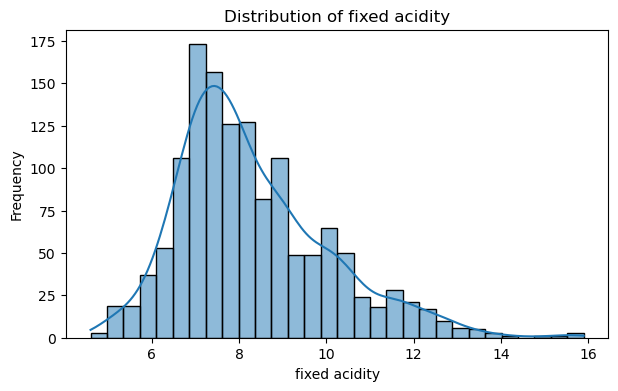

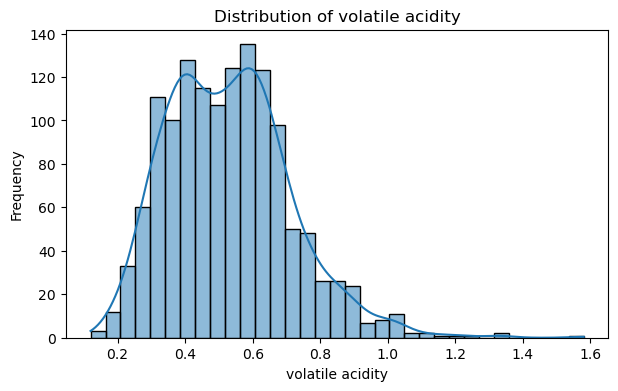

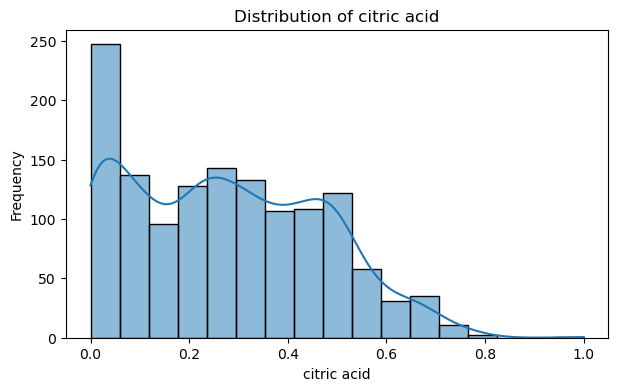

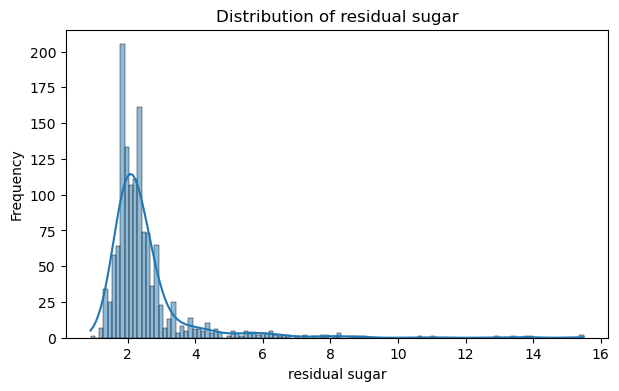

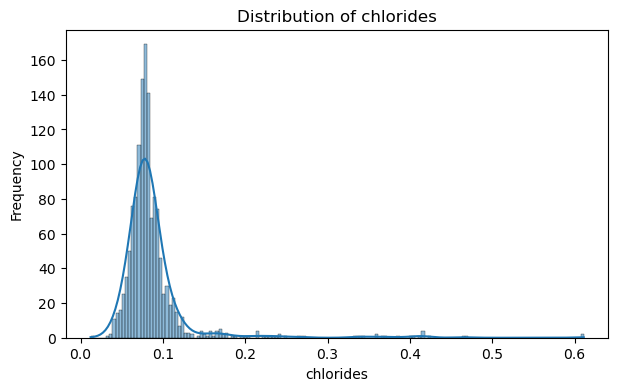

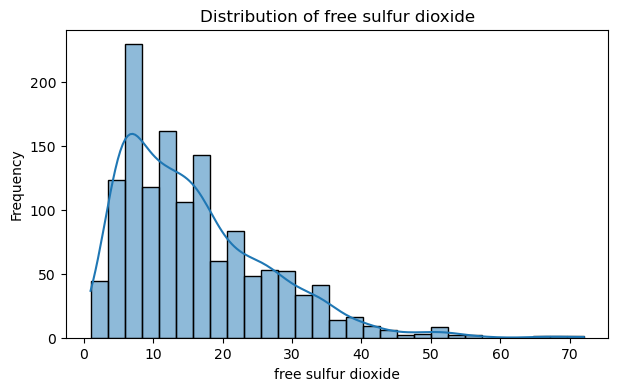

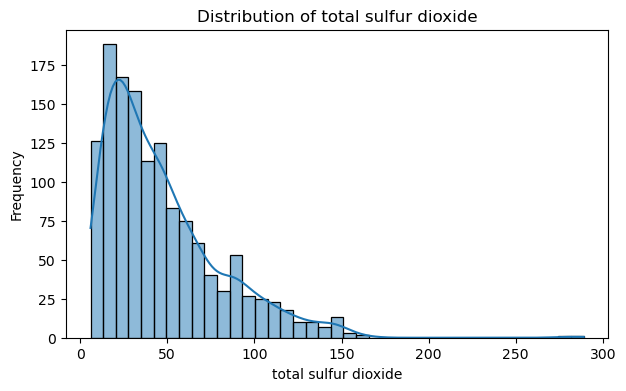

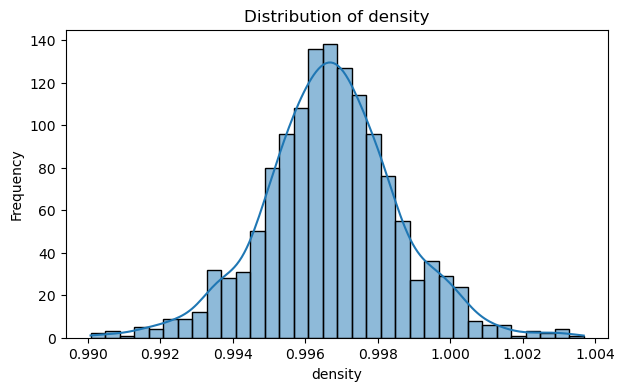

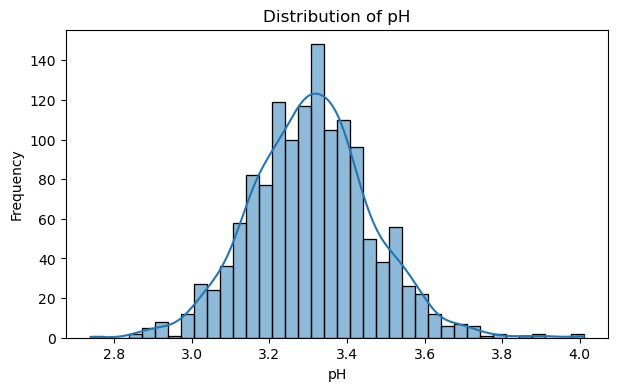

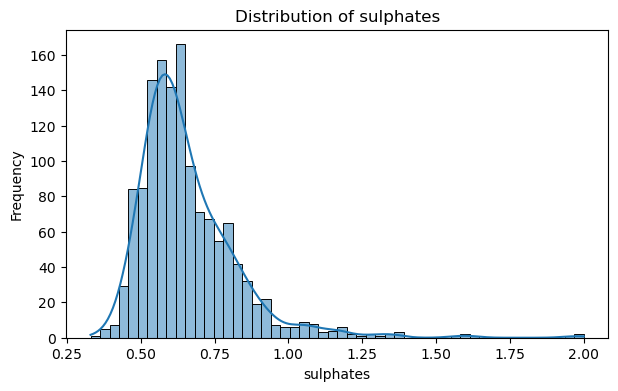

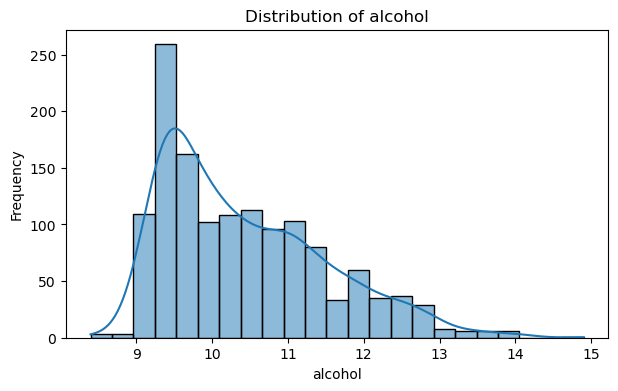

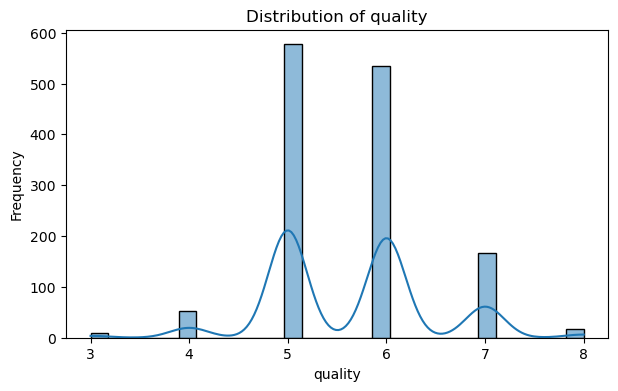

In [24]:
# +kde
numeric_cols=df.columns
for col in numeric_cols:
    plt.figure(figsize=(7,4))
    sns.histplot(df[col],kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

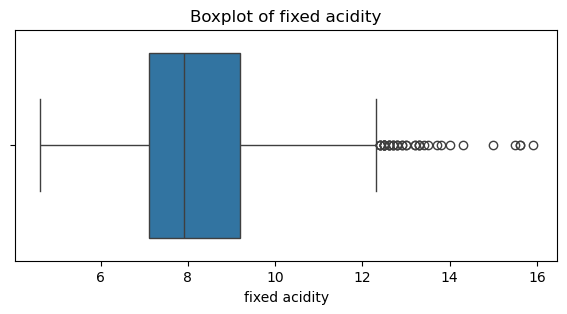

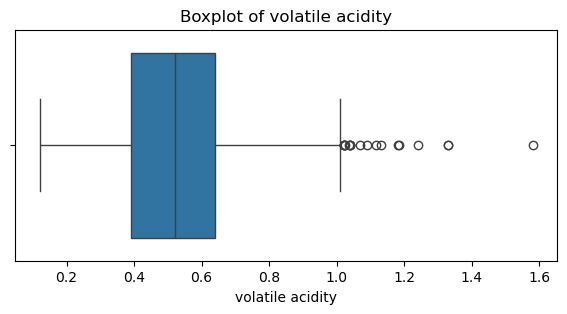

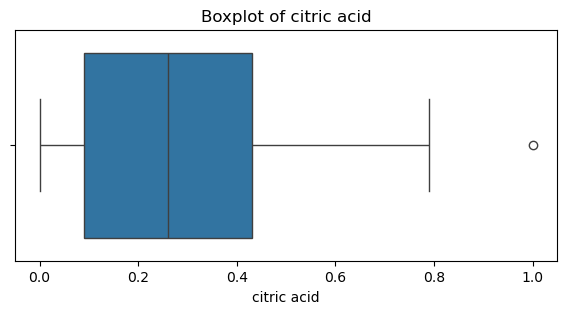

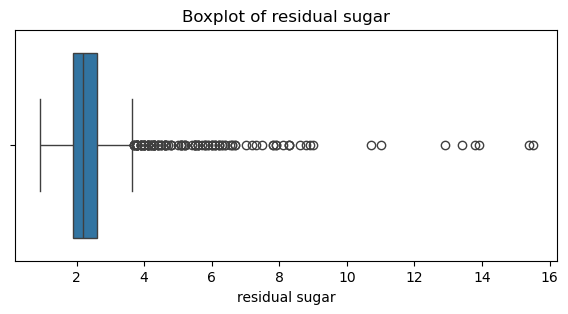

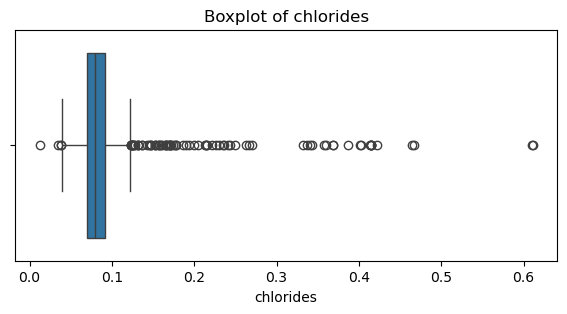

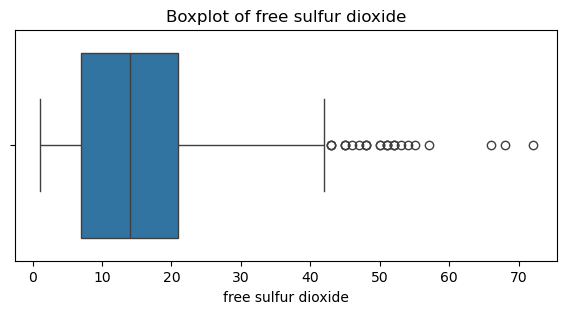

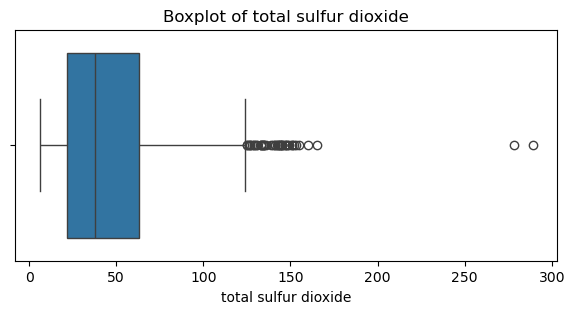

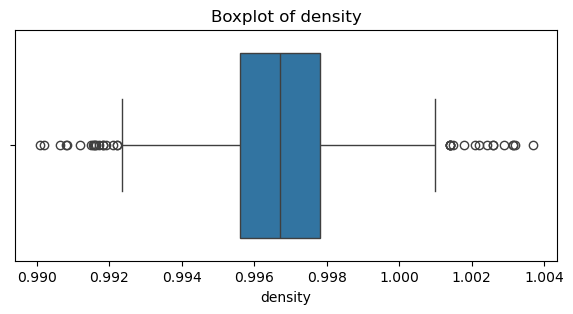

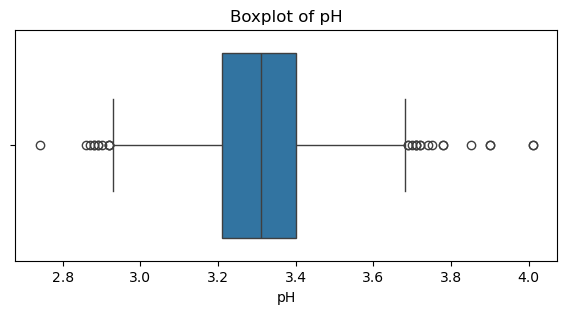

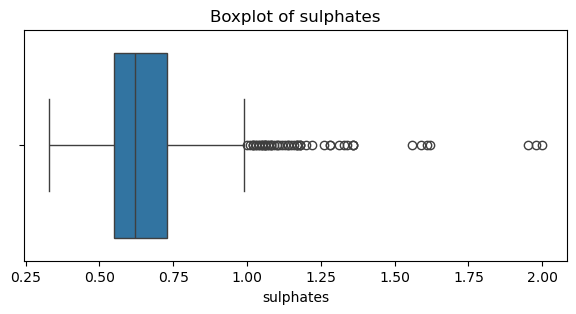

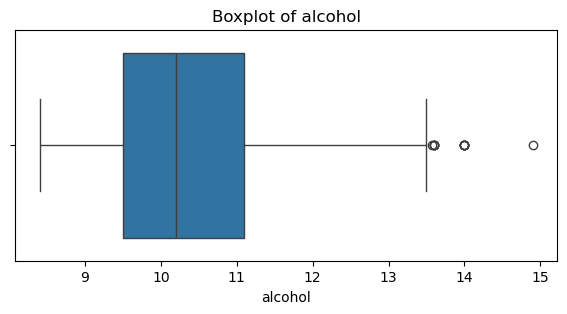

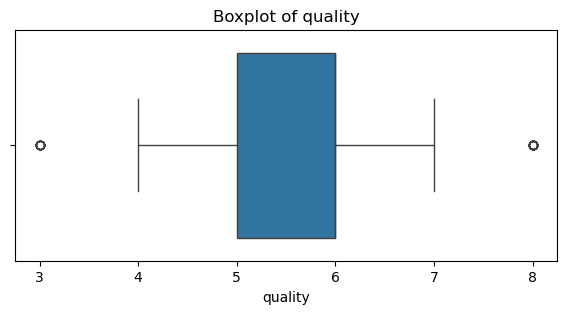

In [26]:
#Box_plot -Outlier Detection
for col in numeric_cols:
    plt.figure(figsize=(7,3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [48]:
#detect outliers for every feature
features=df.drop(columns=['quality'])

Q1=features.quantile(0.25)
Q2=features.quantile(0.75)

IQR=Q2-Q1

lower_bound=Q1-1.5 *IQR
upper_bound=Q2+1.5 *IQR

outlier_mask=(features < lower_bound )| (features > upper_bound)

outlier_count=outlier_mask.sum()

outlier_percentage=(outlier_count / len(features)) *100

outlier_summary=pd.DataFrame({
    'Q1' :Q1,
    'Q2':Q2,
    'IQR':IQR,
    'Lower Bound':lower_bound,
    'Upper Bound':upper_bound,
    'Outlier Count':outlier_count,
    'Outlier %': outlier_percentage
})

outlier_summary.round(3)

,Q1,Q2,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
fixed acidity,7.100,9.200,2.100,3.950,12.350,41,3.017
volatile acidity,0.390,0.640,0.250,0.015,1.015,19,1.398
citric acid,0.090,0.430,0.340,-0.420,0.940,1,0.074
residual sugar,1.900,2.600,0.700,0.850,3.650,126,9.272
chlorides,0.070,0.091,0.021,0.039,0.122,87,6.402
free sulfur dioxide,7.000,21.000,14.000,-14.000,42.000,26,1.913
total sulfur dioxide,22.000,63.000,41.000,-39.500,124.500,45,3.311
density,0.996,0.998,0.002,0.992,1.001,35,2.575
pH,3.210,3.400,0.190,2.925,3.685,28,2.060
sulphates,0.550,0.730,0.180,0.280,1.000,55,4.047


In [32]:
# Number of outliers in each feature

print("Outliers in each feature \n")
for column in features.columns:
    print(f"{column:25s}:{outlier_count[column]}")

Outliers in each feature 

fixed acidity            :41
volatile acidity         :19
citric acid              :1
residual sugar           :126
chlorides                :87
free sulfur dioxide      :26
total sulfur dioxide     :45
density                  :35
pH                       :28
sulphates                :55
alcohol                  :12


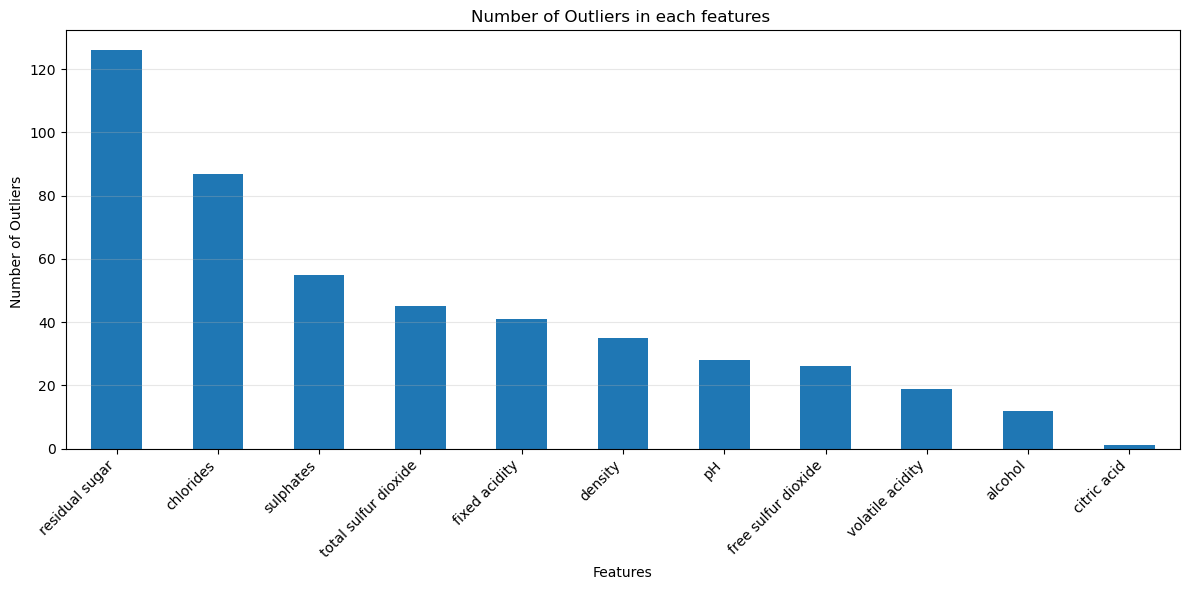

In [52]:
plt.figure(figsize=(12,6))

outlier_count.sort_values(ascending=False).plot(
    kind='bar'
)

plt.title("Number of Outliers in each features ")
plt.xlabel('Features')
plt.ylabel('Number of Outliers ')
plt.xticks(rotation=45,ha='right')
plt.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.show()

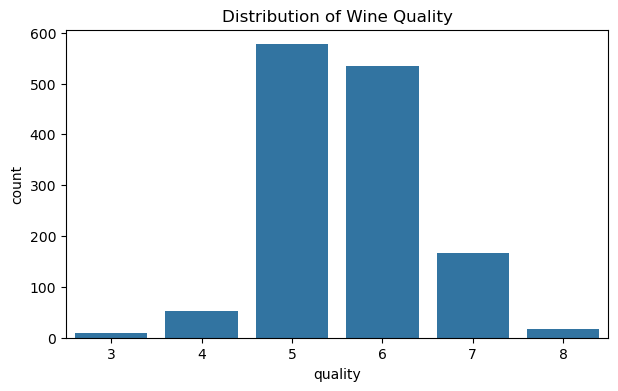

In [55]:
#Quality Distribution

plt.figure(figsize=(7,4))
sns.countplot(x='quality',data=df)
plt.title('Distribution of Wine Quality')
plt.show()

In [58]:
df['quality'].value_counts().sort_index()

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64

###  2. Bivariate Analysis

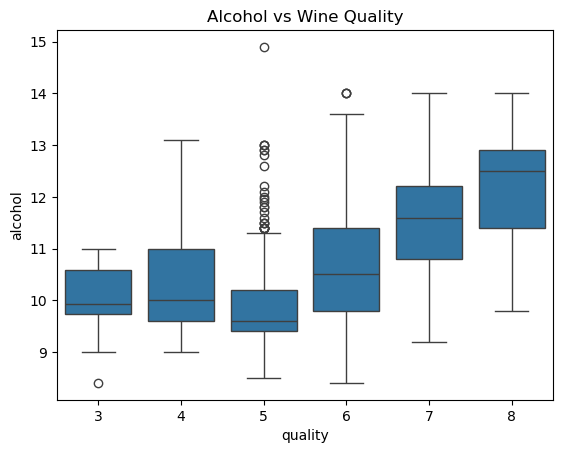

In [60]:
#Alcohol vs Quality

sns.boxplot(x='quality', y='alcohol', data=df)
plt.title('Alcohol vs Wine Quality')
plt.show()

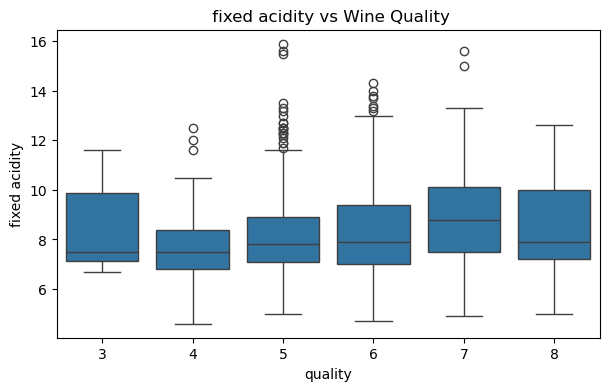

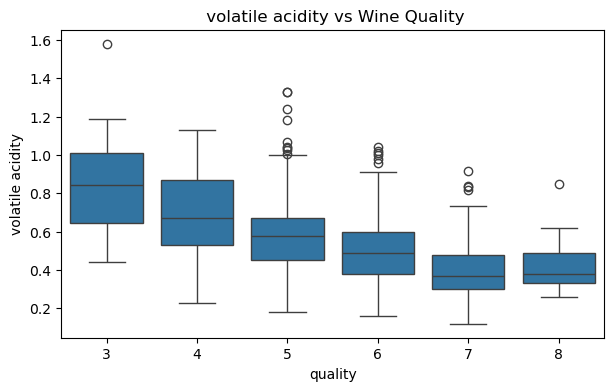

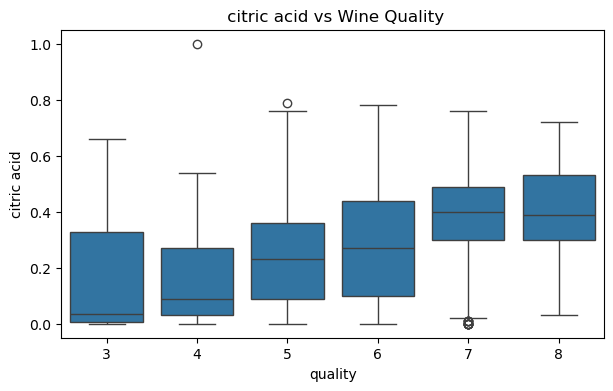

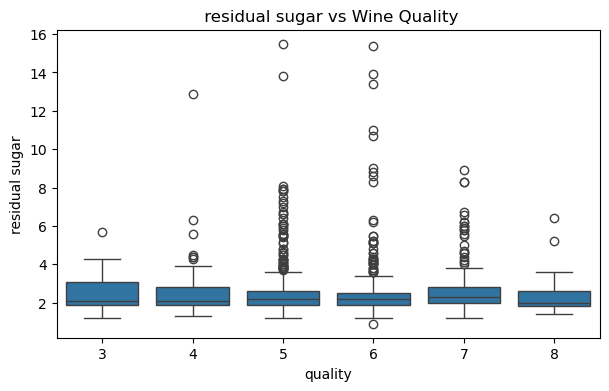

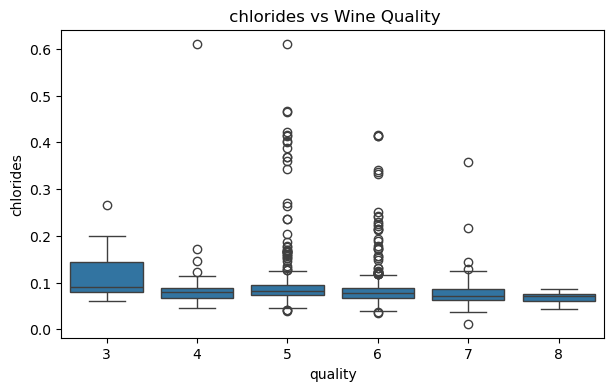

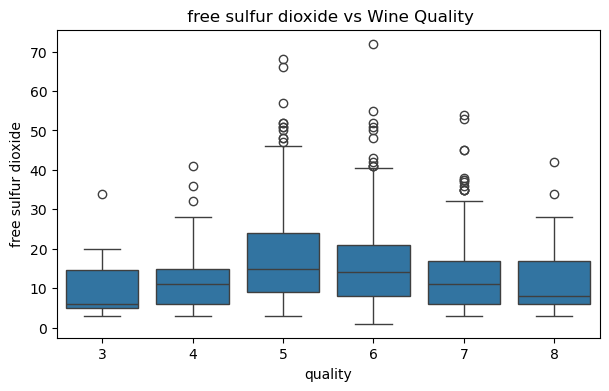

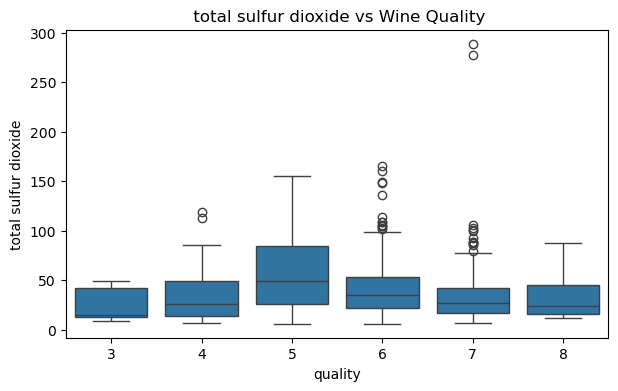

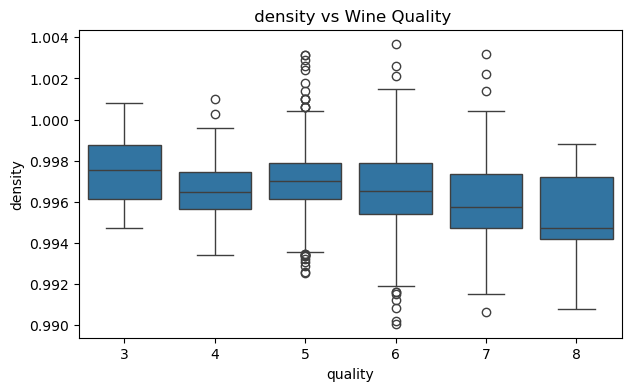

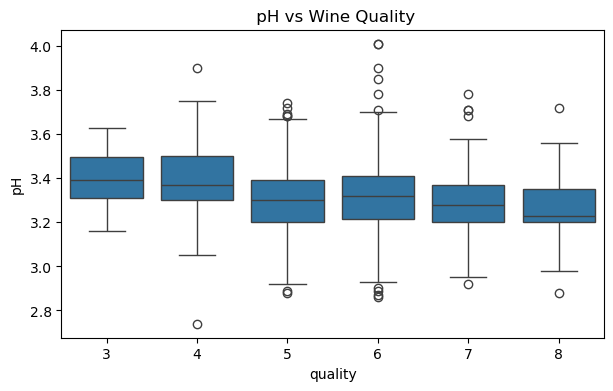

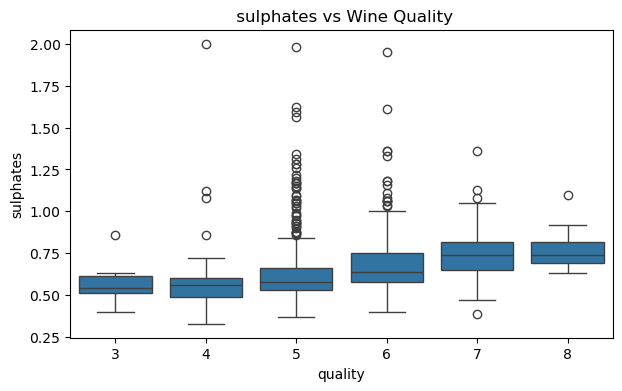

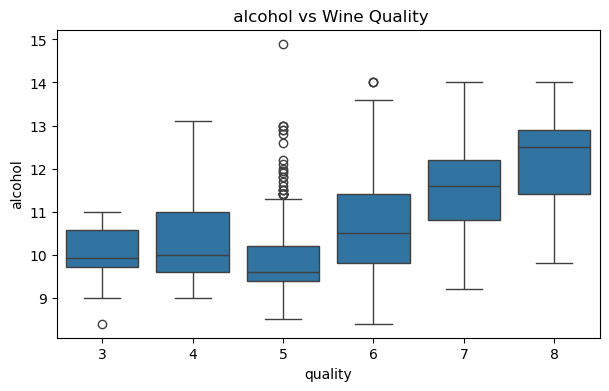

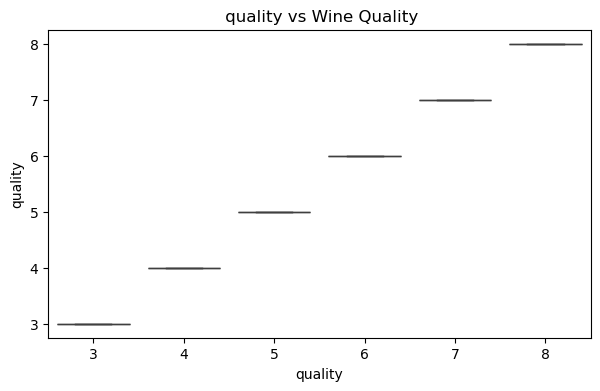

In [62]:
features=['fixed acidity',	'volatile acidity',	'citric acid',	'residual sugar',	
          'chlorides',	'free sulfur dioxide',	'total sulfur dioxide'	, 
          'density'	,'pH', 'sulphates' ,'alcohol',	'quality']
for col in features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x='quality', y=col, data=df)
    plt.title(f' {col} vs Wine Quality')
    plt.show()

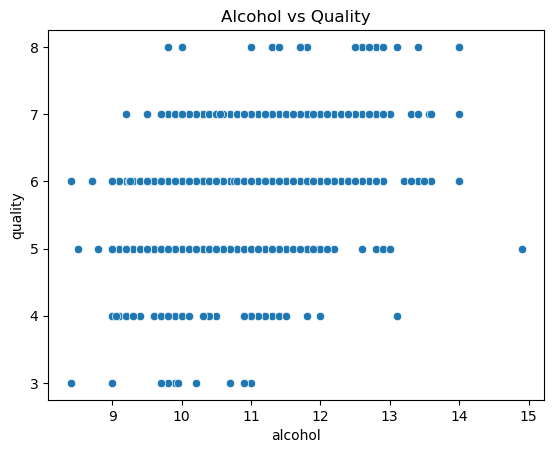

In [63]:
# scatter plot 
sns.scatterplot(x='alcohol',y='quality', data=df)
plt.title('Alcohol vs Quality')
plt.show()

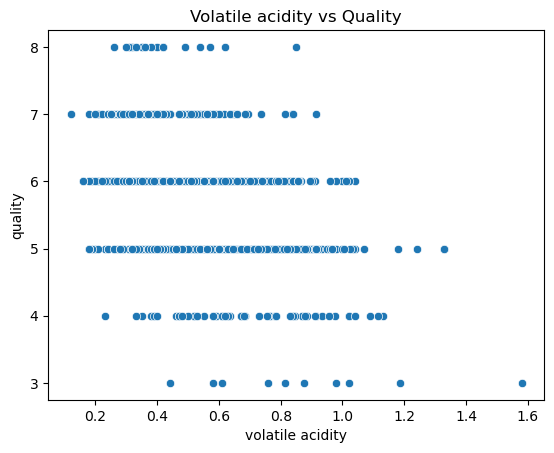

In [65]:
sns.scatterplot(x='volatile acidity',y='quality', data=df)
plt.title('Volatile acidity vs Quality')
plt.show()

### v3. Multivariate Analysis

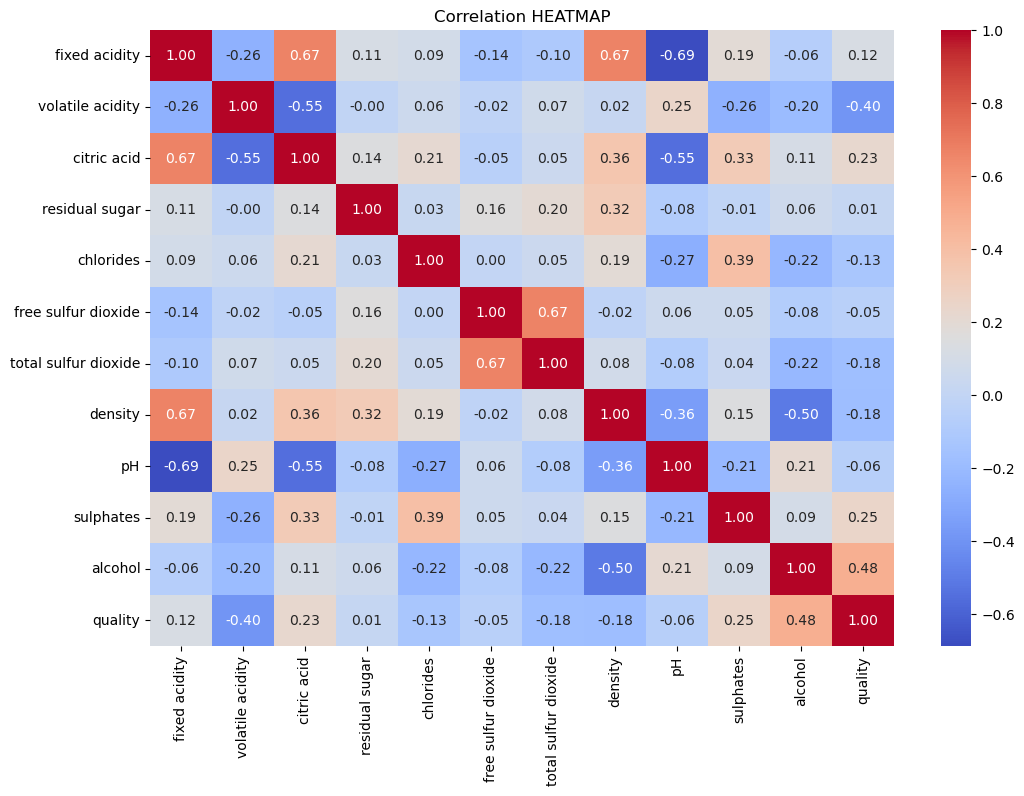

In [68]:
plt.figure(figsize=(12,8))
corr=df.corr()

sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.title("Correlation HEATMAP")
plt.show()

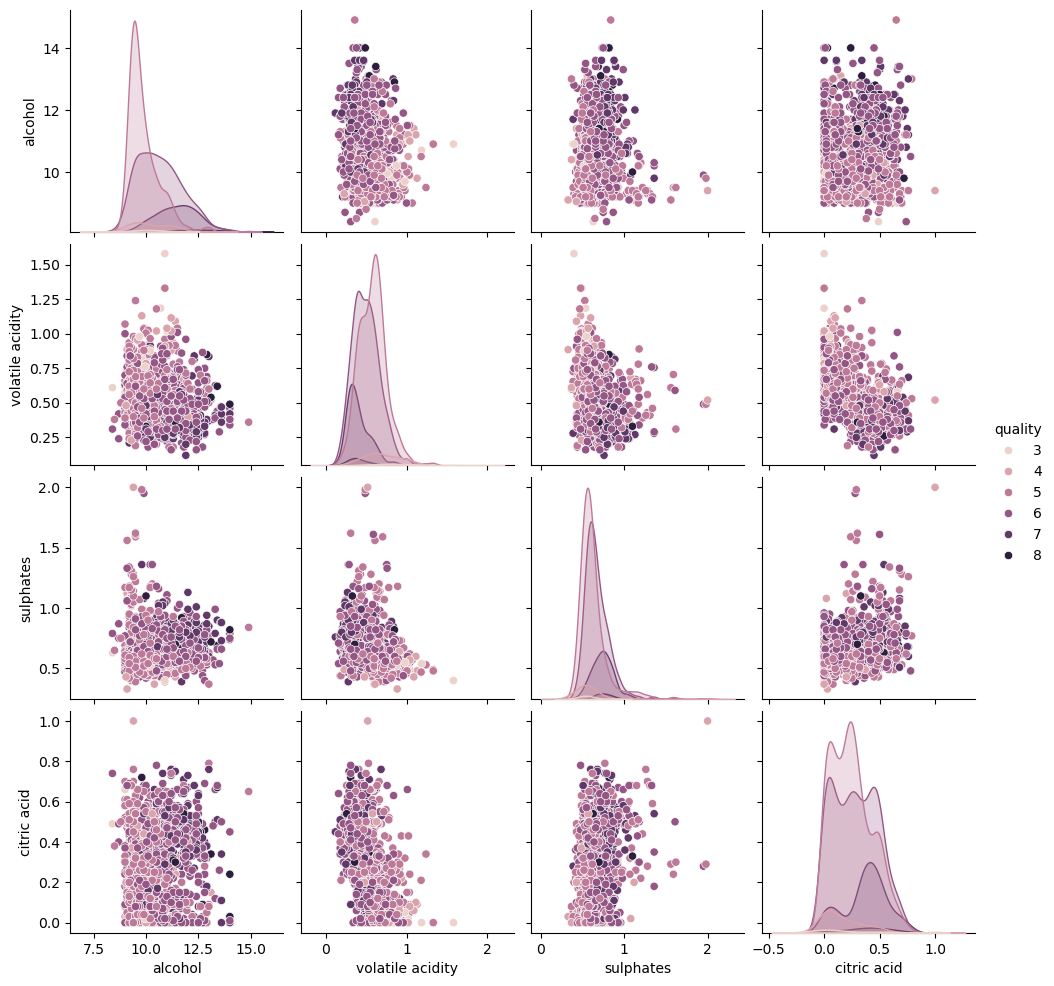

In [70]:
# pair plot
selected=['alcohol','volatile acidity','sulphates','citric acid','quality']
sns.pairplot(df[selected],hue='quality')
plt.show()

In [73]:
# multivariate analysis using Quality Groups
df['quality_group']=pd.cut(df['quality'], bins=[0,5,6,10],labels=['Low','Medium','High']
)

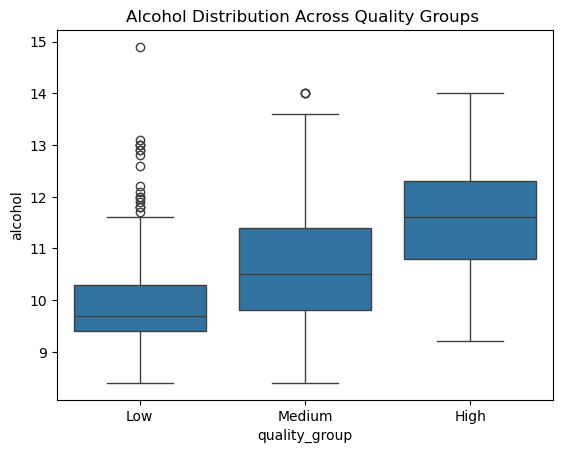

In [75]:
sns.boxplot(x='quality_group',y='alcohol',data=df)
plt.title('Alcohol Distribution Across Quality Groups ')
plt.show()

In [78]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,classification_report,
                            confusion_matrix,ConfusionMatrixDisplay)

In [81]:
X=df.drop('quality',axis=1)
y=df['quality']
print("X shape ",X.shape)
print("y shape ",y.shape)

X shape  (1359, 12)
y shape  (1359,)


In [83]:
print(y.value_counts().sort_index())

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


In [85]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)


In [88]:
criterion='entropy'
dt_model=DecisionTreeClassifier(criterion='entropy',random_state=42)

In [90]:
df['quality_group']=pd.cut(df['quality'], bins=[0,5,6,10],labels=['Low','Medium','High']
)

In [92]:
print(X.columns)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality_group'],
      dtype='object')


In [94]:
print(X.select_dtypes(exclude='number').columns)

Index(['quality_group'], dtype='object')


In [97]:
y=df['quality']
X=df.drop(columns=['quality','quality_group'],errors='ignore')

In [99]:
print(X.columns)
print(X.dtypes)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol'],
      dtype='object')
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
dtype: object


In [105]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [106]:
print(X_train,X_test,y_train,y_test)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
748             7.2              0.50         0.18             2.1      0.071   
1257            7.0              0.58         0.28             4.8      0.085   
16              8.5              0.28         0.56             1.8      0.092   
779             7.1              0.52         0.03             2.6      0.076   
792             7.1              0.61         0.02             2.5      0.081   
...             ...               ...          ...             ...        ...   
1216            7.9              0.57         0.31             2.0      0.079   
241            12.0              0.38         0.56             2.1      0.093   
1276            8.5              0.40         0.40             6.3      0.050   
1516            6.1              0.32         0.25             2.3      0.071   
1135            8.0              0.25         0.43             1.7      0.067   

      free sulfur dioxide  

In [104]:
dt_model=DecisionTreeClassifier(criterion='entropy',random_state=42)
dt_model.fit(X_train,y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [115]:
y_train_pred=dt_model.predict(X_train)
y_test_pred=dt_model.predict(X_test)

In [117]:
train_accuracy=accuracy_score(y_train,y_train_pred)
print("Training Accuracy: ",train_accuracy)

Training Accuracy:  1.0


In [116]:
test_accuracy=accuracy_score(y_test,y_test_pred)
print(test_accuracy)

0.4963235294117647


In [119]:
print("precision:", 
       precision_score(y_test, y_test_pred, average='weighted'))
print("Recall:", 
      recall_score(y_test, y_test_pred, average='weighted'))
print("F1 Score:",
      f1_score(y_test, y_test_pred, average='weighted'))

precision: 0.49434982217769985
Recall: 0.4963235294117647
F1 Score: 0.4951045941835992


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


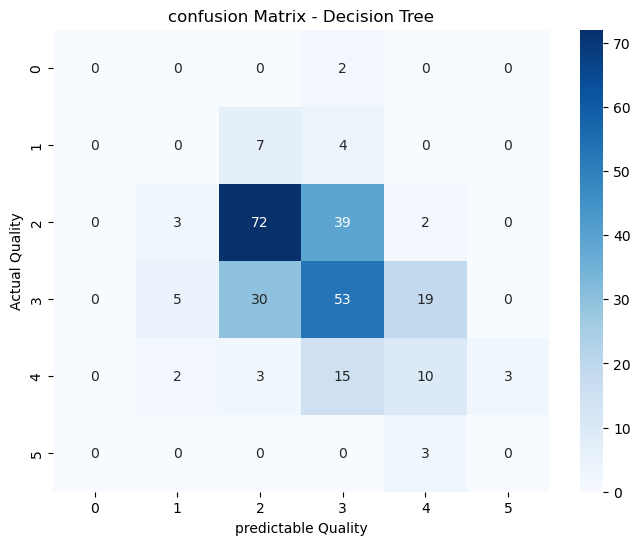

In [120]:
# confusion Matrix

cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8,6))

sns.heatmap(cm, annot=True, fmt='d' , cmap='Blues')

plt.xlabel('predictable Quality')
plt.ylabel('Actual Quality')
plt.title('confusion Matrix - Decision Tree')
plt.show()